In [1]:
import jax
import os

# Avoid OOM errors
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"]=".66"
# os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"]="false"
print(f"JAX backend: {jax.default_backend()}")

JAX backend: gpu


If you don't set the GPU memory allocation, then you can accidentally run out of memory. Sometimes GPU usage is persistant because notebooks, I think.

In [2]:
import sys
sys.path.append("../")

%load_ext autoreload
%autoreload 2

import pulse_simulator as ps

/home/andy/.cache/pypoetry/virtualenvs/pulse-simulator-0UjnMsVt-py3.10/lib/python3.10/site-packages/qiskit_dynamics/dispatch/backends/jax.py:34: UserWarning: The functionality in the perturbation module of Qiskit Dynamics requires a JAX version <= 0.4.6, due to a bug in JAX versions > 0.4.6. For versions 0.4.4, 0.4.5, and 0.4.6, using the perturbation module functionality requires setting os.environ['JAX_JIT_PJIT_API_MERGE'] = '0' before importing JAX or Dynamics.
  warnings.warn(


In [3]:
from datetime import datetime
import functools
import itertools
import logging
import numpy as np
import pickle as pkl
import qiskit as qk
from qiskit import pulse
import qiskit_aer
import qiskit.providers.fake_provider as qk_fp
import qiskit_dynamics as qk_d
import qutip as qt
import re 
from scipy.integrate import simpson
from scipy.linalg import sqrtm, expm
from tqdm import tqdm
import warnings

import matplotlib.pyplot as plt

In [4]:
Units = 1e9

# Undo units
GHz = 1 / Units
MHz = 1e3 / Units
μs = Units / 1e3
ns = Units

backend = qk_fp.FakeManila()
dt = backend.configuration().dt * ns
desired_1qb_duration = 225  # dt
desired_2qb_duration = 225 * 4  # dt

# Gate time in SI units (granularity restriction)
duration_1qb = ps.qiskit_closest_multiple_of_16(desired_1qb_duration * dt / ns, backend)
duration_2qb = ps.qiskit_closest_multiple_of_16(desired_2qb_duration * dt / ns, backend)

# Pulses

We now have a pair of identity gates.

Adjusting X1 to amplitude 0.20078359553005384
Adjusting X2 to amplitude 0.2029490387398391
Adjusting SX1 to amplitude 0.20052729286337825
Adjusting SX2 to amplitude 0.20248564954832834
Adjusting I1 to amplitude 0.2016346225391911


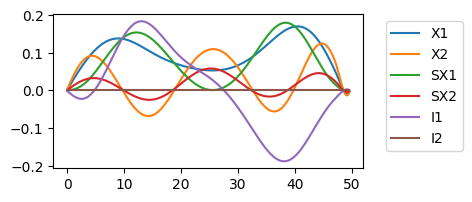

In [5]:
# Load shapes
fname = "../pico-pulses/saved-pulses-2024-02-16/a_single_qubit_gateset_R1e-5.csv"
knames = ["X1", "X2", "SX1", "SX2", "I1"]
pico_a = {k: v for k, v in zip(knames, ps.from_csv(fname))}
# pico_a["I2"] = np.zeros(pico_a["I1"].shape)

# The initial run takes awhile to construct the symbolic pulse shapes
x_gates = {}
for k, v in pico_a.items():
    x_gates[k] = ps.scalable_symbolic_pulse(duration_1qb, v, f"custom-{k}")

# Calibrate the robust X gates
ts = np.arange(0, dt * duration_1qb, dt)
fig, ax = plt.subplots(1, 1, figsize=[4,2])
cal_x_gates = {}
# Only hit the first 4 gates
cal_values = [1.5 * np.pi, 0.5 * np.pi, 1.25 * np.pi, 0.25 * np.pi]
cal_amps = []
for θ, (k, v) in zip(cal_values, x_gates.items()):
    amp = ps.get_amplitude_for_rotation(θ, ps.get_samples(v).real, dt)
    cal_amps.append(amp)
    print(f"Adjusting {k} to amplitude {amp}")
    cal_x_gates[k] = qk.pulse.ScalableSymbolicPulse(
        pulse_type=f"{k}-calibrated",
        duration=duration_1qb,
        amp=amp,
        angle=0.0,
        limit_amplitude=False,
        envelope=v.envelope,
    )
    ax.plot(ts, ps.get_samples(cal_x_gates[k]).real, label=k)

k = "I1"
v = x_gates[k]
amp = np.median(cal_amps)
print(f"Adjusting {k} to amplitude {amp}")
cal_x_gates[k] = qk.pulse.ScalableSymbolicPulse(
        pulse_type=f"{k}-calibrated",
        duration=duration_1qb,
        amp=amp,
        angle=0.0,
        limit_amplitude=False,
        envelope=v.envelope,
)
ax.plot(ts, ps.get_samples(cal_x_gates[k]).real, label=k)

k = "I2"
v = ps.zero_envelope(duration_1qb)
cal_x_gates[k] = qk.pulse.ScalableSymbolicPulse(
        pulse_type=f"{k}-calibrated",
        duration=duration_1qb,
        amp=0.0,
        angle=0.0,
        limit_amplitude=False,
        envelope=v.envelope,
)
ax.plot(ts, ps.get_samples(cal_x_gates[k]).real, label=k)

# Add legend
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

# Calibrate the default X gates
default_gates = {}
for k in pico_a.keys():
    if "SX" in k:
        default_gates[k] = ps.gaussian_envelope(duration_1qb, dt=dt, angle=np.pi / 4)
    elif "X" in k:
        default_gates[k] = ps.gaussian_envelope(duration_1qb, dt=dt, angle=np.pi / 2)
    elif "I" in k:
        default_gates[k] = ps.zero_envelope(duration_1qb)
    else:
        raise ValueError(f"Unknown gate {k}")
default_gates["I2"] = ps.zero_envelope(duration_1qb)


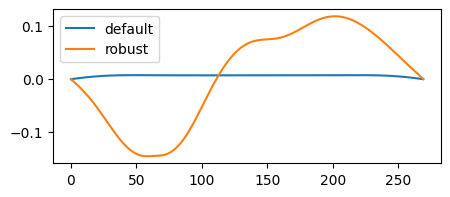

In [6]:
# Load shapes
def fname(k):
    return f"../pico-pulses/saved-pulses-2024-01-16/a_two_qubit_{k}.csv"
knames = ["default", "robust"]
pico2_a = {k: ps.from_csv(fname(k))[0] for k in knames}

# Less precise about optimization than before...
fig, ax = plt.subplots(figsize=[5, 2])
for k, v in pico2_a.items():
    ax.plot(v, label=k)
ax.legend()

# Downsample the pulse to make construction faster
cr_gates = {}
for k, v in pico2_a.items():
    cr_gates[k] = ps.scalable_symbolic_pulse(
        duration_2qb,
        ps.resample(51, v, keep_step=False),
        f"cr-{k}"
    )

# Add positive and negative rotations to gateset
cal_cr_gates = {}
cal_values = [0.125 * np.pi, 0.125 * np.pi]
for θ, (k, v) in zip(cal_values, cr_gates.items()):
    amp = ps.get_amplitude_for_rotation(θ, ps.get_samples(v).real, dt)
    cal_cr_gates[k] = {
        "+": qk.pulse.ScalableSymbolicPulse(
            pulse_type=f"{k}-calibrated+amp",
            duration=duration_2qb,
            amp=amp,
            angle=0.0,
            limit_amplitude=False,
            envelope=v.envelope,
        ),
        "-": qk.pulse.ScalableSymbolicPulse(
            pulse_type=f"{k}-calibrated-amp",
            duration=duration_2qb,
            amp=-amp,
            angle=0.0,
            limit_amplitude=False,
            envelope=v.envelope,
        ),
    }

# Circuits

In [7]:
# Set the parameters globally for the model
N = 4  # number of spins
hz = 1.0 * 2 * np.pi  # magnetic field along z
Jx = 1.0 * 2 * np.pi  # Coupling along x
Δt = 0.05  # time step for integration


def create_initial_state(qr, cr):
    '''
    Creates the initial state for the experiment.
    Here we would like to prepare the |+>|+>|+>|+> state.
    '''
    circ = qk.QuantumCircuit(qr, cr)
    [circ.h(qr[i]) for i in range(qr.size)]
    return circ


def rxx(circ, θx, q1, q2):
    '''
    Implements the exp(-i theta/2 sx_1 sx_2) gate.
    '''
    circ.cx(q1, q2)
    circ.rx(θx, q1)
    circ.cx(q1, q2)
    return circ


def first_order_Trotter_unitary(circ, Δt, barrier=False):
    '''
    Applies a Unitary for a single time step U(Δt) using first-order trotter expansion to the input quantum circuit.
    input : circ is a quantum circuit
    output : circ-U(Δt)-
    '''
    # Layer A: coupling XX between n and n+1
    # Induce parallel CR gates
    if barrier:
        circ.barrier()
    for p in range(0, circ.num_qubits - 1, 2):
        circ = rxx(circ, Jx * Δt, circ.qubits[p], circ.qubits[p + 1])
    if barrier:
        circ.barrier()
    for p in range(1, circ.num_qubits - 1, 2):
        circ = rxx(circ, Jx * Δt, circ.qubits[p], circ.qubits[p + 1])

    #  Alt., a naive loop will apply XX rotations sequentially, failing to stack.
    # for p in range(0, circ.num_qubits - 1):
    #     circ = rxx(circ, Jx * Δt, circ.qubits[p], circ.qubits[p + 1])

    # Layer B: on-site Z
    for p in range(circ.num_qubits):    
        circ.rz(hz*Δt, circ.qubits[p])

    return circ


def second_order_Trotter_unitary(circ, Δt, barrier=False):
    '''
    Applies a Unitary for a single time step U(Δt) using second-order trotter expansion to the input quantum circuit.
    input : circ is a quantum circuit
    output : circ-U(Δt)-
    '''
    # Layer 2: on-site Z (half)
    for p in range(circ.num_qubits):
        circ.rz(hz * Δt / 2, circ.qubits[p])
 
    # Layer 1: coupling XX between n and n+1
    # Induce parallel structure (and symmetry)
    for p in range(1, circ.num_qubits - 1, 2):
        circ = rxx(circ, Jx * Δt / 2, circ.qubits[p], circ.qubits[p+1])
    # NOTE: Add barriers to separate the parallel section
    if barrier:
        circ.barrier()
    for p in range(0, circ.num_qubits - 1, 2):
        circ = rxx(circ, Jx * Δt, circ.qubits[p], circ.qubits[p+1])
    if barrier:
        circ.barrier()
    for p in range(1, circ.num_qubits - 1, 2):
        circ = rxx(circ, Jx * Δt / 2, circ.qubits[p], circ.qubits[p+1])

    # Layer 2: on-site Z (half)
    for p in range(circ.num_qubits):
        circ.rz(hz * Δt / 2, circ.qubits[p])
    return circ

/home/andy/.cache/pypoetry/virtualenvs/pulse-simulator-0UjnMsVt-py3.10/lib/python3.10/site-packages/qiskit/quantum_info/operators/measures.py:399: UserWarning: Treating array input as a SuperOp object
  warnings.warn(f"Treating array input as a {fallback_class.__name__} object")
/home/andy/.cache/pypoetry/virtualenvs/pulse-simulator-0UjnMsVt-py3.10/lib/python3.10/site-packages/qiskit/quantum_info/operators/measures.py:399: UserWarning: Treating array input as a Operator object
  warnings.warn(f"Treating array input as a {fallback_class.__name__} object")
/home/andy/.cache/pypoetry/virtualenvs/pulse-simulator-0UjnMsVt-py3.10/lib/python3.10/site-packages/qiskit/visualization/circuit/matplotlib.py:266: FutureWarning: The default matplotlib drawer scheme will be changed to "iqp" in a following release. To silence this warning, specify the current default explicitly as style="clifford", or the new default as style="iqp".
  self._style, def_font_ratio = load_style(self._style)


Fidelity:  1.0000000000000022


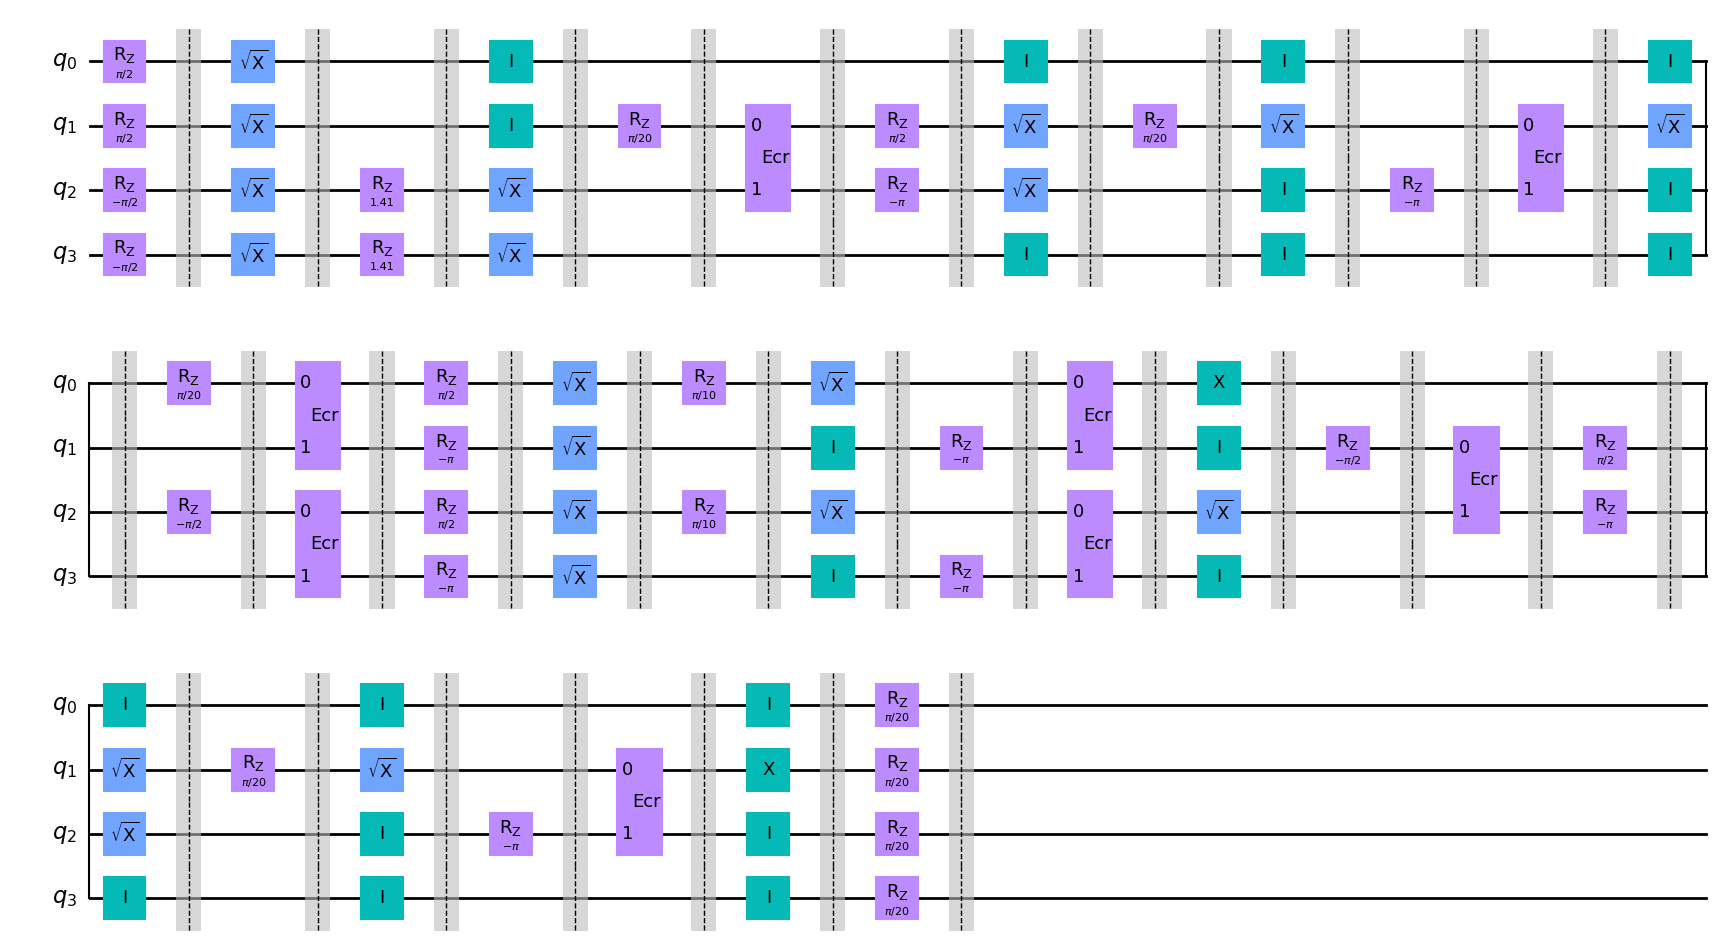

In [8]:
# """
# Test the circuit with identity gates inserted
# """


registers = [0, 1, 2, 3]

qr = qk.QuantumRegister(len(registers))
cr = qk.ClassicalRegister(len(registers))
circ = create_initial_state(qr, cr)
circ = second_order_Trotter_unitary(circ, Δt)

mb = ps.MomentBuilder()
my_moments = mb.build_moments(circ)
my_moments_prev = np.copy(my_moments)

# Add in explicit identity gates
for m in my_moments:
    if ps.get_moment_case(m) == "single":
        missing = [i for i in range(len(registers)) if i not in m.keys()]
        for k in missing:
            m[k] = "I1" if k % 2 == 0 else "I2"

circ1 = ps.build_circuit(my_moments_prev, registers, barriers=True)
circ2 = ps.build_circuit(my_moments, registers, barriers=True)
print("Fidelity: ", qk.quantum_info.process_fidelity(circ1, circ2))
circ2.draw('mpl')

# ps.build_pulse_schedule(my_moments, cal_x_gates, cal_cr_gates['robust'], registers, backend, dt).draw()

### Other circuits

The circuit is 11 layers deep. Let's just play 11 layers of 4 qubits of X gates.

# Models

In [9]:
scale = 1.0


# Set registers above with circuit
# The rest is automatic
# ===================== 

# NOTE: If the Rabi rates are True, you have to calibrate!
cvars = ps.backend_simulation_vars(backend, rabi=False, units=Units)

# Change T1 and T2 to match Eagle processors like Sherbrooke
for k, v in cvars.items():
    if "t1" in k:
        cvars[k] = 250 / μs * ns
    if "t2" in k:
        cvars[k] = 150 / μs * ns

# Carrier frequencies of each control line
# NOTE: We won't use carriers in this example
carriers = ps.backend_carriers(backend, cvars)

# Partially compile model functions with parameters
# =====
H_rx = functools.partial(
    ps.rx_model,
    registers=registers,
    backend=backend,
    variables=cvars,
    rotating_frame=True,
)

H_rz = functools.partial(
    ps.rz_model,
    registers=registers,
    backend=backend,
)

H_cr = functools.partial(
    ps.cross_resonance_model,
    registers=registers,
    backend=backend,
    variables=cvars,
    model_name="Toy",
)

A_decay = functools.partial(ps.qubit_decay_model, registers=registers, variables=cvars)

edges = ps.backend_edges(backend) #[1:-1]
print(f"Edges: {edges}")
H_xtalk = scale * ps.crosstalk_model(registers, edges, cvars)

# Create a system model
# =====
H_drift = 0.0
Hs_control = []
Hs_channels = []
As_static = []
for qubit in registers:
    # Single qubit terms
    Hj_drift, Hjs_control, Hjs_channel = H_rx(qubit)
    Hj_phase, Hj_phase_ch = H_rz(qubit)
    Ajs_static = A_decay(qubit)

    H_drift += Hj_drift
    Hs_control += Hjs_control + [Hj_phase]
    Hs_channels += Hjs_channel + [Hj_phase_ch]
    As_static += Ajs_static

    # Two qubit with ring connectivity
    if qubit < len(registers) - 1:
        control, target = qubit, qubit + 1
        
        # Get both directions
        for pair in [(control, target), (target, control)]:
            Hj_drift, Hjs_control, Hjs_channel = H_cr(pair)
            H_drift += Hj_drift
            Hs_control += Hjs_control
            Hs_channels += Hjs_channel

# Some models may repeat control channels
# NOTE: This actually really matters! Repeat channels mess things up.
Hs_channels, indices = np.unique(Hs_channels, return_index=True)
Hs_control = [Hs_control[i] for i in indices]

# For RWA / Rotating frame
# NOTE: We won't use carriers in this example
# =====
registered_carriers = {c: 0 for c in Hs_channels}
cutoff_freq = None

# registered_carriers = {c: carriers[c] for c in Hs_channels}
# cutoff_freq = 2 * np.mean(list(registered_carriers.values()))

Edges: [(0, 1), (1, 2), (2, 3), (3, 4)]


In [10]:
sched = ps.build_pulse_schedule(
    my_moments,
    qubit_gates=default_gates,
    cr_gates=cal_cr_gates['default'],
    registers=registers,
    backend=backend,
    name="hamiltonian-simulation",
    dt=dt
)

robust_sched = ps.build_pulse_schedule(
    my_moments,
    qubit_gates=cal_x_gates,
    cr_gates=cal_cr_gates['robust'],
    registers=registers,
    backend=backend,
    name="hamiltonian-simulation",
    dt=dt
)

mix_sched = ps.build_pulse_schedule(
    my_moments,
    qubit_gates=default_gates,
    cr_gates=cal_cr_gates['robust'],
    registers=registers,
    backend=backend,
    name="hamiltonian-simulation",
    dt=dt
)

# Check durations
assert robust_sched.duration == sched.duration

# Would be nice to disable phase channels when plotting
# sched.draw()

# Solvers

In [11]:
# Models already in the rotating frame
# =====

solver_r0 = qk_d.Solver(
    static_hamiltonian=None,
    hamiltonian_operators=Hs_control,
    hamiltonian_channels=Hs_channels,
    # static_dissipators=As_static,
    rotating_frame=None,
    rwa_cutoff_freq=None,
    channel_carrier_freqs=registered_carriers,
    dt=dt
)

solver_r = qk_d.Solver(
    static_hamiltonian=None,
    hamiltonian_operators=Hs_control,
    hamiltonian_channels=Hs_channels,
    static_dissipators=As_static,
    rotating_frame=None,
    rwa_cutoff_freq=None,
    channel_carrier_freqs=registered_carriers,
    dt=dt
)

solver_rx0 = qk_d.Solver(
    static_hamiltonian=H_xtalk,
    hamiltonian_operators=Hs_control,
    hamiltonian_channels=Hs_channels,
    # static_dissipators=As_static,
    rotating_frame=None,
    rwa_cutoff_freq=None,
    channel_carrier_freqs=registered_carriers,
    dt=dt
)

solver_rx = qk_d.Solver(
    static_hamiltonian=H_xtalk,
    hamiltonian_operators=Hs_control,
    hamiltonian_channels=Hs_channels,
    static_dissipators=As_static,
    rotating_frame=None,
    rwa_cutoff_freq=None,
    channel_carrier_freqs=registered_carriers,
    dt=dt
)

# Unitary simulations

In [22]:
# measure after each non-phase moment
measure_times = dt * np.cumsum(
    ps.durations_of_moments(my_moments, cal_x_gates, cal_cr_gates['default'])
)[[ps.get_moment_case(m) != "phase" for m in my_moments]]
# and at the end time...
measure_times = np.append(measure_times, sched.duration * dt)


# targets at measure times
Uts = []
for i, m in enumerate(my_moments):
    if ps.get_moment_case(m) != "phase":
        Uts.append(ps.build_operator(my_moments[0:i+1], registers))
# and at the end time...
Uts.append(qk.quantum_info.Operator(ps.build_circuit(my_moments, registers)))

# Target
target = Uts[-1]

In [13]:
print("Case 2: Crosstalk, no decay")

y0 = ps.qiskit_identity_operator(len(registers))

# labels = ["robust (rotary)"]
# all_schedules = [robust_sched]

# labels = ["robust (rotary)",  "default (rotary)"]
# all_schedules = [robust_sched, mix_sched]

labels = ["default", "robust (rotary)", "default (rotary)"]
all_schedules = [sched, robust_sched, mix_sched]


# ==========

solver_rx0.model.evaluation_mode = "dense"
res_x0 = solver_rx0.solve(
    t_span=[0.0, sched.duration * dt],
    t_eval=measure_times,
    y0=y0,
    signals=all_schedules,
    atol=1e-9,
    rtol=1e-9,
    method="jax_odeint",
)

# Compute fidelity (we can use our circuit to compute the target)
target = qk.quantum_info.Operator(ps.build_circuit(my_moments, registers))

for i, ell in enumerate(labels):
    print(f"\tInfidelity of {ell}: ", 1 - qk.quantum_info.process_fidelity(res_x0[i].y[-1], target))

Case 2: Crosstalk, no decay


 -4.85684920e-08 -4.59937081e-08 -4.09080430e-08 -3.79771928e-08
 -3.51840044e-08 -3.37378367e-08 -3.07780940e-08 -2.81488444e-08
 -2.53385491e-08 -2.16349220e-08 -1.97940075e-08 -1.49466564e-08]
 -5.03051296e-08 -4.67044863e-08 -4.15536166e-08 -3.97458832e-08
 -3.62242092e-08 -3.48730791e-08 -3.24395429e-08 -2.89282444e-08
 -2.62765920e-08 -2.34351991e-08 -2.16783181e-08 -1.60605263e-08]
 -4.69200520e-08 -4.31559079e-08 -3.82991140e-08 -3.61292581e-08
 -3.25294558e-08 -3.15325864e-08 -2.90958639e-08 -2.53764982e-08
 -2.27669653e-08 -1.92148595e-08 -1.83556101e-08 -1.27567649e-08]


	Infidelity of default:  0.04010315484840454
	Infidelity of robust (rotary):  9.060067404953465e-05
	Infidelity of default (rotary):  0.003442418885015508


 -1.27233786e-08 -1.27184951e-08]
 -1.26939266e-08 -1.26890455e-08]
 -1.71455642e-08 -1.71406672e-08 -1.38995317e-08 -1.38494102e-08
 -1.18860210e-08 -1.18220711e-08]
 -1.70851301e-08 -1.70802403e-08 -1.38390407e-08 -1.37889137e-08
 -1.18255427e-08 -1.17615931e-08]
 -1.87842455e-08 -1.86719403e-08 -1.58300291e-08 -1.57489704e-08
 -1.36884157e-08 -1.35537842e-08 -1.15007452e-08 -1.14007767e-08]
 -2.33081479e-08 -2.13786972e-08 -1.88234370e-08 -1.84105427e-08
 -1.57986328e-08 -1.52147502e-08 -1.35884929e-08 -1.24814701e-08
 -1.13971931e-08 -1.06072043e-08]
 -2.37431120e-08 -2.19556562e-08 -1.93113276e-08 -1.87554406e-08
 -1.63734220e-08 -1.58290229e-08 -1.39900651e-08 -1.30210788e-08
 -1.19058770e-08 -1.12173137e-08]
 -3.33777621e-08 -3.12568215e-08 -3.09210044e-08 -2.38989305e-08
 -2.30656245e-08 -2.18131429e-08 -2.14915742e-08 -1.83148295e-08
 -1.71260135e-08 -1.35525274e-08 -1.27490084e-08]
 -3.33159272e-08 -3.11831771e-08 -3.08408551e-08 -2.38380136e-08
 -2.30028620e-08 -2.17603071e-

 -1.23239734e-08 -1.23177847e-08]
 -1.22948920e-08 -1.22887022e-08]
 -1.60996649e-08 -1.60934341e-08 -1.28979306e-08 -1.28480347e-08
 -1.08512700e-08 -1.07936733e-08]
 -1.60403980e-08 -1.60341782e-08 -1.28385874e-08 -1.27886881e-08
 -1.07919186e-08 -1.07343281e-08]
 -1.73697129e-08 -1.72758249e-08 -1.42992540e-08 -1.42599192e-08
 -1.23064048e-08 -1.21850904e-08 -1.02661196e-08 -1.02046001e-08]
 -2.22707793e-08 -2.01285823e-08 -1.73008101e-08 -1.69772583e-08
 -1.42900996e-08 -1.39296834e-08 -1.21649931e-08 -1.12302800e-08
 -1.02244293e-08]
 -2.27713204e-08 -2.07702186e-08 -1.78402615e-08 -1.73248816e-08
 -1.48923873e-08 -1.45748923e-08 -1.26160559e-08 -1.18061318e-08
 -1.07619275e-08]
 -3.22354201e-08 -2.88155251e-08 -2.86291743e-08 -2.28230266e-08
 -2.19578821e-08 -1.97427916e-08 -1.94316970e-08 -1.66050739e-08
 -1.52585743e-08 -1.25433322e-08 -1.09190722e-08]
 -3.21736380e-08 -2.87520585e-08 -2.85362027e-08 -2.27629062e-08
 -2.18892062e-08 -1.96976175e-08 -1.93727067e-08 -1.65496726e-

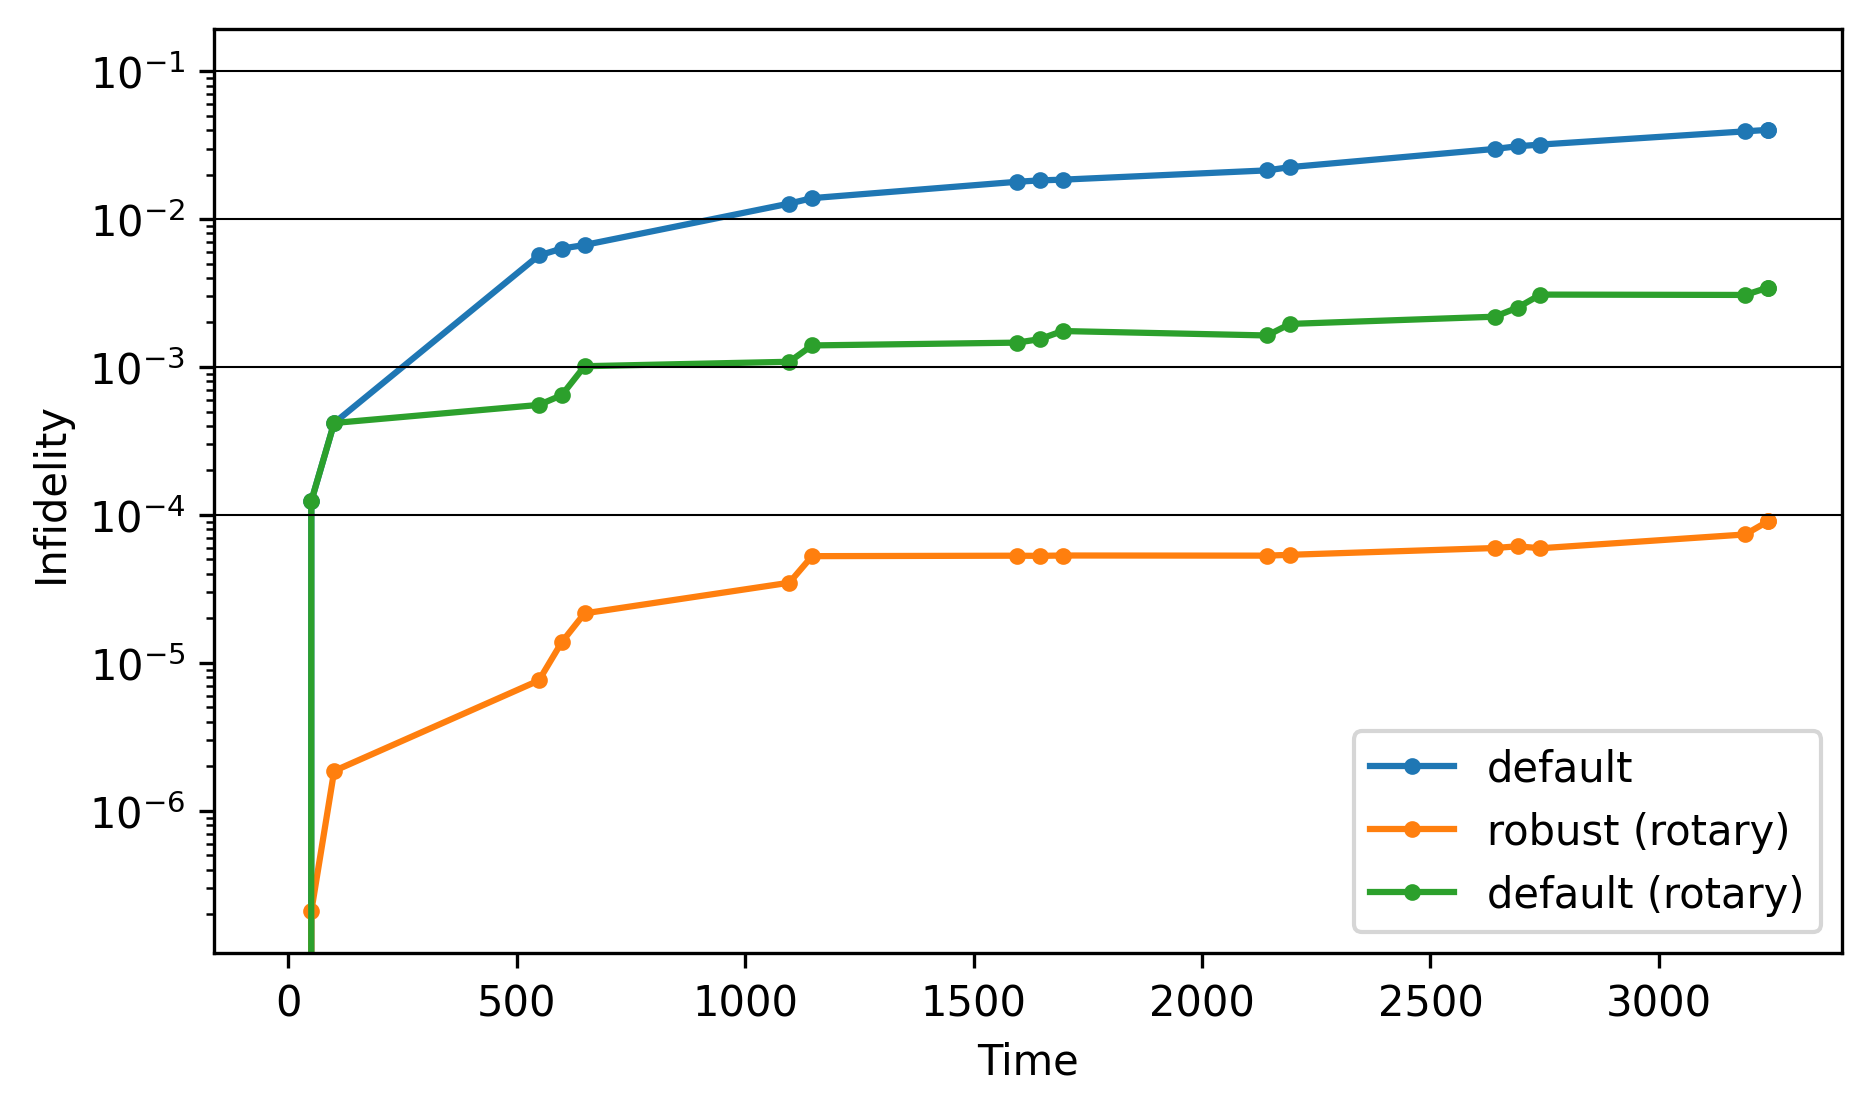

In [14]:
fig, axes = plt.subplots(1, figsize=[7, 4], dpi=300)
axes = axes if isinstance(axes, np.ndarray) else [axes]
# axes[0].set_title("Hamiltonian simulation: Crosstalk, No decoherence", loc='left')


for iax in range(1):
    ax = axes[iax]

    for i, res in enumerate(res_x0):
        infids = [0]
        # if labels[i] == "default":
        #     continue
        for r, t in zip(res.y, Uts):
            infids.append(1 - qk.quantum_info.process_fidelity(qk.quantum_info.Operator(r), qk.quantum_info.Operator(t)))
        ax.plot(np.hstack([0, *measure_times]), infids, label=labels[i], marker=".")

    ax.axhline(0.1, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.01, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.001, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.0001, color="black", linestyle="-", lw=0.5)

    ax.set_xlabel("Time")
    if iax == 0:
        ax.legend(loc="lower right")
        ax.set_yscale("log")
        ax.set_ylabel("Infidelity")
    else:
        ax.set_ylabel("Infidelity")
        ax.legend(loc="upper left")
        ax.set_yscale("linear")

### Plots for layers of Hamiltonian simulation

This is the crosstalk-free sim and plot. We won't need that sim for now.

This is the plot for the crosstalk example. We're still using that simulation up above.

 -4.85684920e-08 -4.59937081e-08 -4.09080430e-08 -3.79771928e-08
 -3.51840044e-08 -3.37378367e-08 -3.07780940e-08 -2.81488444e-08
 -2.53385491e-08 -2.16349220e-08 -1.97940075e-08 -1.49466564e-08]
 -1.01735052e-07 -9.57002999e-08 -9.23253962e-08 -8.20236988e-08
 -7.52903459e-08 -6.95061340e-08 -6.75803000e-08 -6.27113116e-08
 -5.62600661e-08 -5.23194006e-08 -4.87528341e-08 -4.07693440e-08]
 -1.44924871e-07 -1.41539102e-07 -1.37093061e-07 -1.24542595e-07
 -1.13252942e-07 -1.04397391e-07 -1.01479102e-07 -9.45533561e-08
 -8.48266374e-08 -7.94894027e-08 -7.37612328e-08 -6.01791754e-08]
 -2.02849974e-07 -1.91054909e-07 -1.84542418e-07 -1.64874744e-07
 -1.51614002e-07 -1.42551334e-07 -1.37873728e-07 -1.28270073e-07
 -1.13818816e-07 -1.05840085e-07 -1.01459656e-07 -8.44204508e-08]
 -2.44562273e-07 -2.38065513e-07 -2.29692187e-07 -2.08319074e-07
 -1.90623963e-07 -1.80195045e-07 -1.73920849e-07 -1.62556768e-07
 -1.43321319e-07 -1.35137799e-07 -1.27838152e-07 -1.06793193e-07]
 -3.03511712e-07 -2.

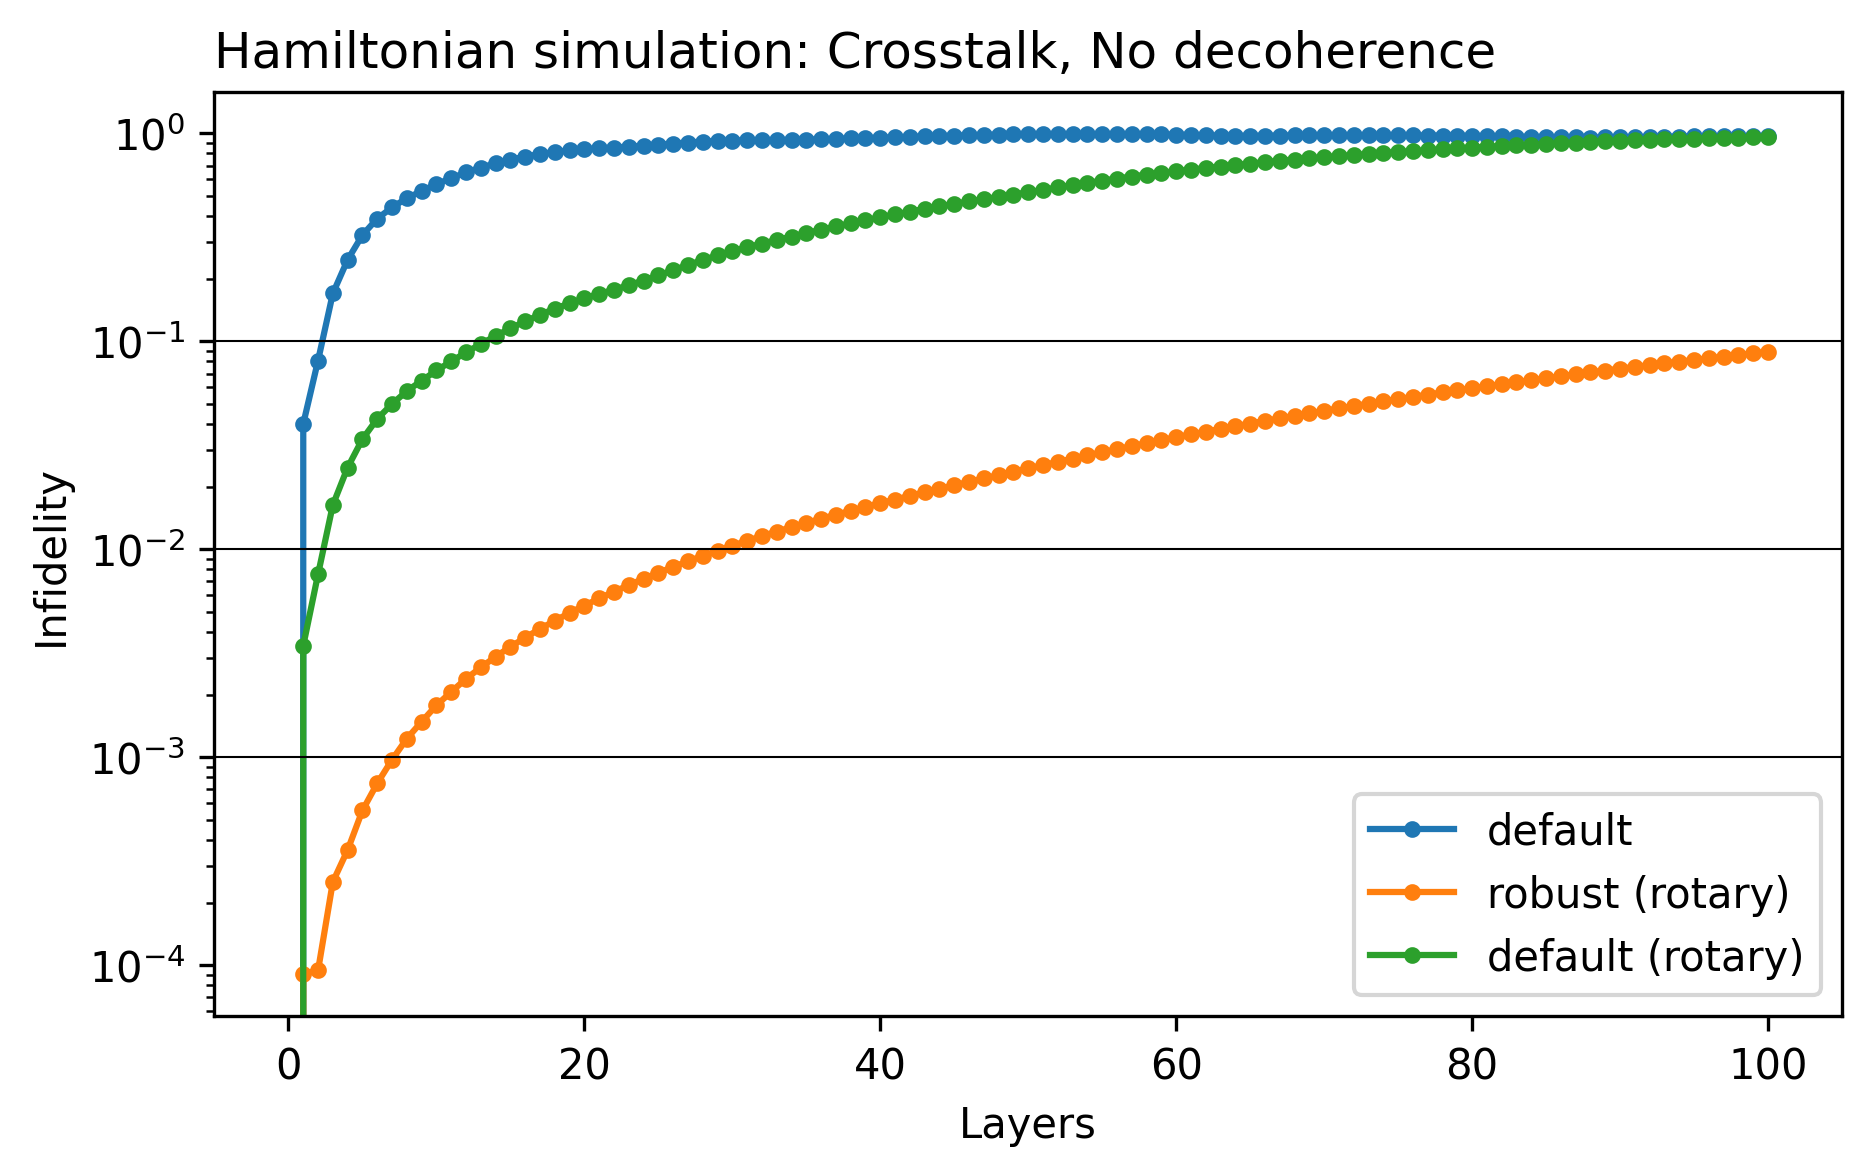

In [15]:
n = 100

fig, axes = plt.subplots(1, figsize=[7, 4], dpi=300)
axes = axes if isinstance(axes, np.ndarray) else [axes]
# fig.suptitle("Hamiltonian simulation")
axes[0].set_title("Hamiltonian simulation: Crosstalk, No decoherence", loc='left')

# NOTE: Manually add a layer 0 for the initial state
layers = np.arange(0, n + 1)
Ulayers = list(itertools.accumulate(np.repeat([target], n, axis=0), np.matmul))

for iax in range(1):
    ax = axes[iax]

    for i, res in enumerate(res_x0):
        # if labels[i] == "default":
        #     continue

        Ufs = itertools.accumulate(np.repeat([res.y[-1]], n, axis=0), np.matmul)
        infids = [0]
        for u, t in zip(Ufs, Ulayers):
            infids.append(1 - qk.quantum_info.process_fidelity(qk.quantum_info.Operator(u), qk.quantum_info.Operator(t)))
        # Labels set previously
        ax.plot(layers, infids, label=labels[i], marker=".")

    ax.axhline(0.1, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.01, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.001, color="black", linestyle="-", lw=0.5)

    ax.set_xlabel("Layers")
    if iax == 0:
        ax.legend(loc="lower right")
        ax.set_yscale("log")
        ax.set_ylabel("Infidelity")
    else:
        ax.set_ylabel("Infidelity")
        ax.legend(loc="upper left")
        ax.set_yscale("linear")

### With decoherence

In [16]:
print("Case 3: Crosstalk and Decoherence")

# y0 = ps.qiskit_identity_operator(len(registers), open=True)
y0 = ps.qiskit_ground_state(len(registers), open=True)

labels = ["default", "robust (rotary)", "default (rotary)"]
schedules = [sched, robust_sched, mix_sched]

solver_rx.model.evaluation_mode = "dense"
res_x = solver_rx.solve(
    t_span=[0.0, sched.duration * dt],
    t_eval=measure_times,
    y0=y0,
    signals=schedules,
    atol=1e-9,
    rtol=1e-9,
    method="jax_odeint",
)

# Compute fidelity (we can use our circuit to compute the target)
target = qk.quantum_info.Operator(ps.build_circuit(my_moments, registers))
y_target = y0.evolve(target)

# for i in range(len(res_x)):
#     print(
#         f"\tInfidelity of {labels[i]} schedule: {1 - qk.quantum_info.process_fidelity(res_x[0].y[-1], target)}"
#     )

for i in range(len(res_x)):
    print(
        f"\tInfidelity of {labels[i]} schedule: {1 - qk.quantum_info.state_fidelity(res_x[i].y[-1], y_target)}"
    )

Case 3: Crosstalk and Decoherence
	Infidelity of default schedule: 0.08089455755647768
	Infidelity of robust (rotary) schedule: 0.04149483806086085
	Infidelity of default (rotary) schedule: 0.044335722827888224


In [17]:
print("Case 3.5: Decoherence")

# y0 = ps.qiskit_identity_operator(len(registers), open=True)
y0 = ps.qiskit_ground_state(len(registers), open=True)

labels = ["decoherence limit, default", "decoherence limit, robust (rotary)", "decoherence limit, default (rotary)"]
schedules = [sched, robust_sched, mix_sched]

solver_r.model.evaluation_mode = "dense"
res_r = solver_r.solve(
    t_span=[0.0, sched.duration * dt],
    t_eval=measure_times,
    y0=y0,
    signals=schedules,
    atol=1e-9,
    rtol=1e-9,
    method="jax_odeint",
)

# Compute fidelity (we can use our circuit to compute the target)
target = qk.quantum_info.Operator(ps.build_circuit(my_moments, registers))
y_target = y0.evolve(target)

for i in range(len(res_r)):
    print(
        f"\tInfidelity of {labels[i]} schedule: {1 - qk.quantum_info.state_fidelity(res_r[i].y[-1], y_target)}"
    )

Case 3.5: Decoherence
	Infidelity of decoherence limit, default schedule: 0.04155893995929538
	Infidelity of decoherence limit, robust (rotary) schedule: 0.04148320363505531
	Infidelity of decoherence limit, default (rotary) schedule: 0.04137076335740941


In [18]:
# Save the results
# format datetime for a file name
now = datetime.now()
dt_string = now.strftime("%Y-%m-%d-%H-%M-%S")
pkl.dump(
    {
        "res_x0": res_x0,
        "res_x": res_x,
        "res_r": res_r,
        "measure_times": measure_times,
        "Uts": Uts,
    },
    open(f"../playground/{dt_string}-scale-{scale}-crosstalk-decoherence.pkl", "wb"),
)

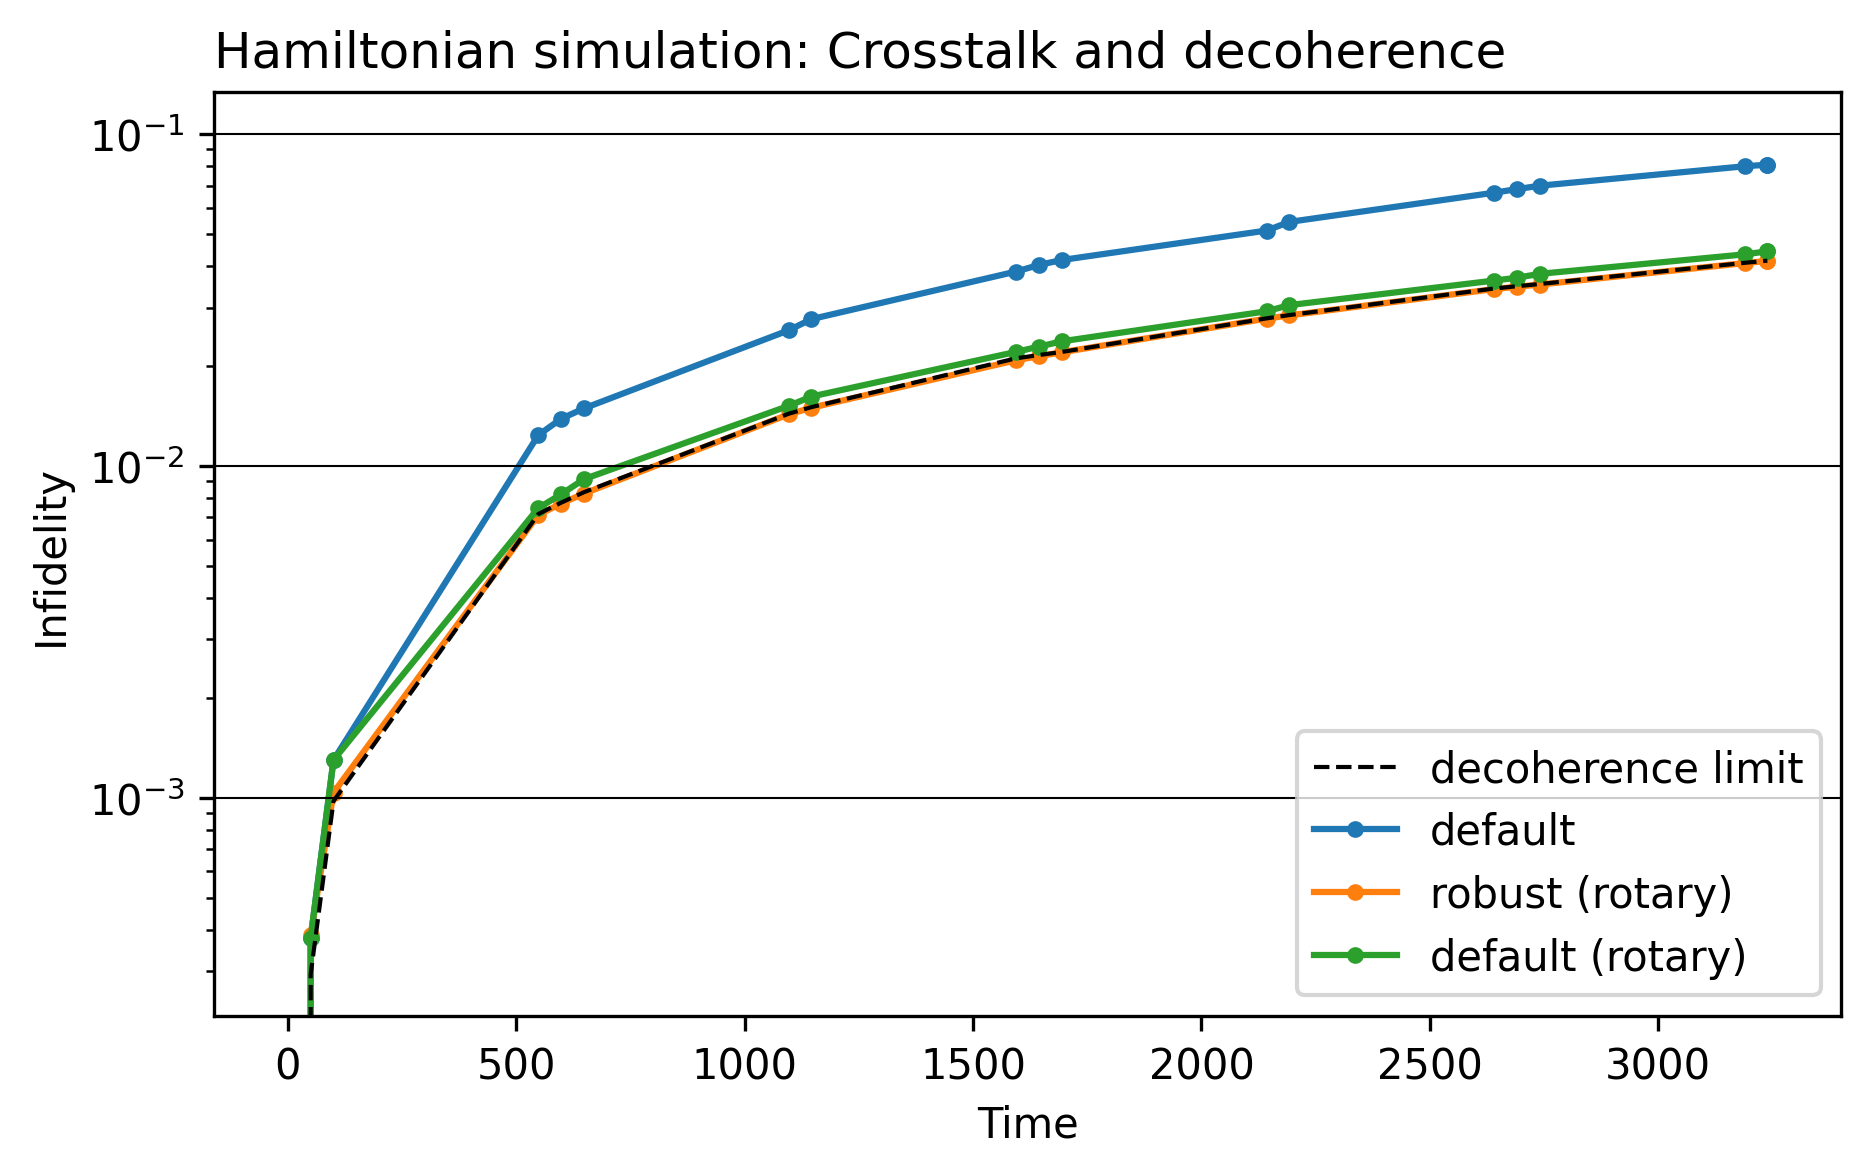

In [23]:
fig, axes = plt.subplots(1, figsize=[7, 4], dpi=300)
axes = axes if isinstance(axes, np.ndarray) else [axes]
axes[0].set_title("Hamiltonian simulation: Crosstalk and decoherence", loc='left')

yts = [y0.evolve(Ut) for Ut in Uts]
labels = ["default", "robust (rotary)", "default (rotary)"]
# labels = ["decoherence limit, default", "decoherence limit, robust (rotary)", "decoherence limit, default (rotary)"]

for iax in range(len(axes)):
    ax = axes[iax]
    tab10 = plt.get_cmap("tab10")
    for i, (rx, rr) in enumerate(zip(res_x, res_r)):
        infids = [0]
        infids_decoh = [0]
        for j, t in enumerate(yts):
            infids.append(1 - qk.quantum_info.state_fidelity(rx.y[j], t))
            infids_decoh.append(1 - qk.quantum_info.state_fidelity(rr.y[j], t))
        if i == 0:
            ax.plot(np.hstack([0, *measure_times]), infids_decoh, c='k', ls='--',lw=1, zorder=10, label="decoherence limit")
        ax.plot(np.hstack([0, *measure_times]), infids, c=tab10(i), label=labels[i], marker=".")

    ax.axhline(0.1, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.01, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.001, color="black", linestyle="-", lw=0.5)

    ax.set_xlabel("Time")
    if iax == 0:
        ax.legend(loc="lower right")
        ax.set_yscale("log")
        ax.set_ylabel("Infidelity")
    else:
        ax.set_ylabel("Infidelity")
        ax.legend(loc="upper left")
        ax.set_yscale("linear")

# Combo plot

In [26]:
# Load from file
two_res_x0 = []
two_res_x = []
two_res_r = []
with open("../playground/2024-03-01-15-06-33-scale-10-crosstalk-decoherence.pkl", "rb") as f:
    data = pkl.load(f)
    two_res_x0.append(data['res_x0'])
    two_res_x.append(data['res_x'])
    two_res_r.append(data['res_r'])

with open("../playground/2024-03-01-15-36-13-scale-1.0-crosstalk-decoherence.pkl", "rb") as f:
    data = pkl.load(f)
    two_res_x0.append(data['res_x0'])
    two_res_x.append(data['res_x'])
    two_res_r.append(data['res_r'])

 -1.37180012e-08 -1.36238433e-08 -1.09455939e-08 -1.08507000e-08]
 -1.27233786e-08 -1.27184951e-08]
 -1.36876204e-08 -1.35927341e-08 -1.09152404e-08 -1.08195494e-08]
 -1.26939266e-08 -1.26890455e-08]
 -1.80633356e-08 -1.79668368e-08 -1.52885606e-08 -1.51945469e-08
 -1.25107168e-08 -1.16086975e-08]
 -1.71455642e-08 -1.71406672e-08 -1.38995317e-08 -1.38494102e-08
 -1.18860210e-08 -1.18220711e-08]
 -1.80035621e-08 -1.79063103e-08 -1.52277131e-08 -1.51333452e-08
 -1.24542871e-08 -1.15517634e-08]
 -1.70851301e-08 -1.70802403e-08 -1.38390407e-08 -1.37889137e-08
 -1.18255427e-08 -1.17615931e-08]
 -2.02654312e-08 -1.96921907e-08 -1.75118842e-08 -1.68205670e-08
 -1.47645975e-08 -1.33681398e-08 -1.13159151e-08 -1.06747386e-08]
 -1.87842455e-08 -1.86719403e-08 -1.58300291e-08 -1.57489704e-08
 -1.36884157e-08 -1.35537842e-08 -1.15007452e-08 -1.14007767e-08]
 -2.36547073e-08 -2.28997440e-08 -2.09878745e-08 -1.91411279e-08
 -1.69023916e-08 -1.49947351e-08 -1.35243368e-08 -1.23899785e-08
 -1.07310749

 -1.32852184e-08 -1.31647750e-08 -1.01533650e-08]
 -1.31797496e-08 -1.31205259e-08]
 -1.34263513e-08 -1.33043987e-08 -1.02851354e-08 -1.00931121e-08]
 -1.33218285e-08 -1.32571215e-08 -1.00919038e-08 -1.00262255e-08]
 -1.79179129e-08 -1.77800270e-08 -1.48617050e-08 -1.46177683e-08
 -1.27117858e-08 -1.25872439e-08 -1.05520209e-08 -1.04051423e-08]
 -1.74629193e-08 -1.73888556e-08 -1.42694021e-08 -1.41872073e-08
 -1.22422290e-08 -1.21761908e-08 -1.01894364e-08 -1.01256747e-08]
 -1.80667516e-08 -1.79238678e-08 -1.50286948e-08 -1.47735138e-08
 -1.28205003e-08 -1.26837772e-08 -1.06420840e-08 -1.05030251e-08]
 -1.75606608e-08 -1.74856427e-08 -1.43797888e-08 -1.42949679e-08
 -1.23202467e-08 -1.22544306e-08 -1.02549018e-08 -1.01929887e-08]
 -1.95504229e-08 -1.93570692e-08 -1.64146659e-08 -1.61078061e-08
 -1.45242626e-08 -1.43452261e-08 -1.23053332e-08 -1.20382162e-08]
 -1.90065064e-08 -1.88790863e-08 -1.57789338e-08 -1.56796714e-08
 -1.39754693e-08 -1.38641745e-08 -1.18495939e-08 -1.17757819e-08

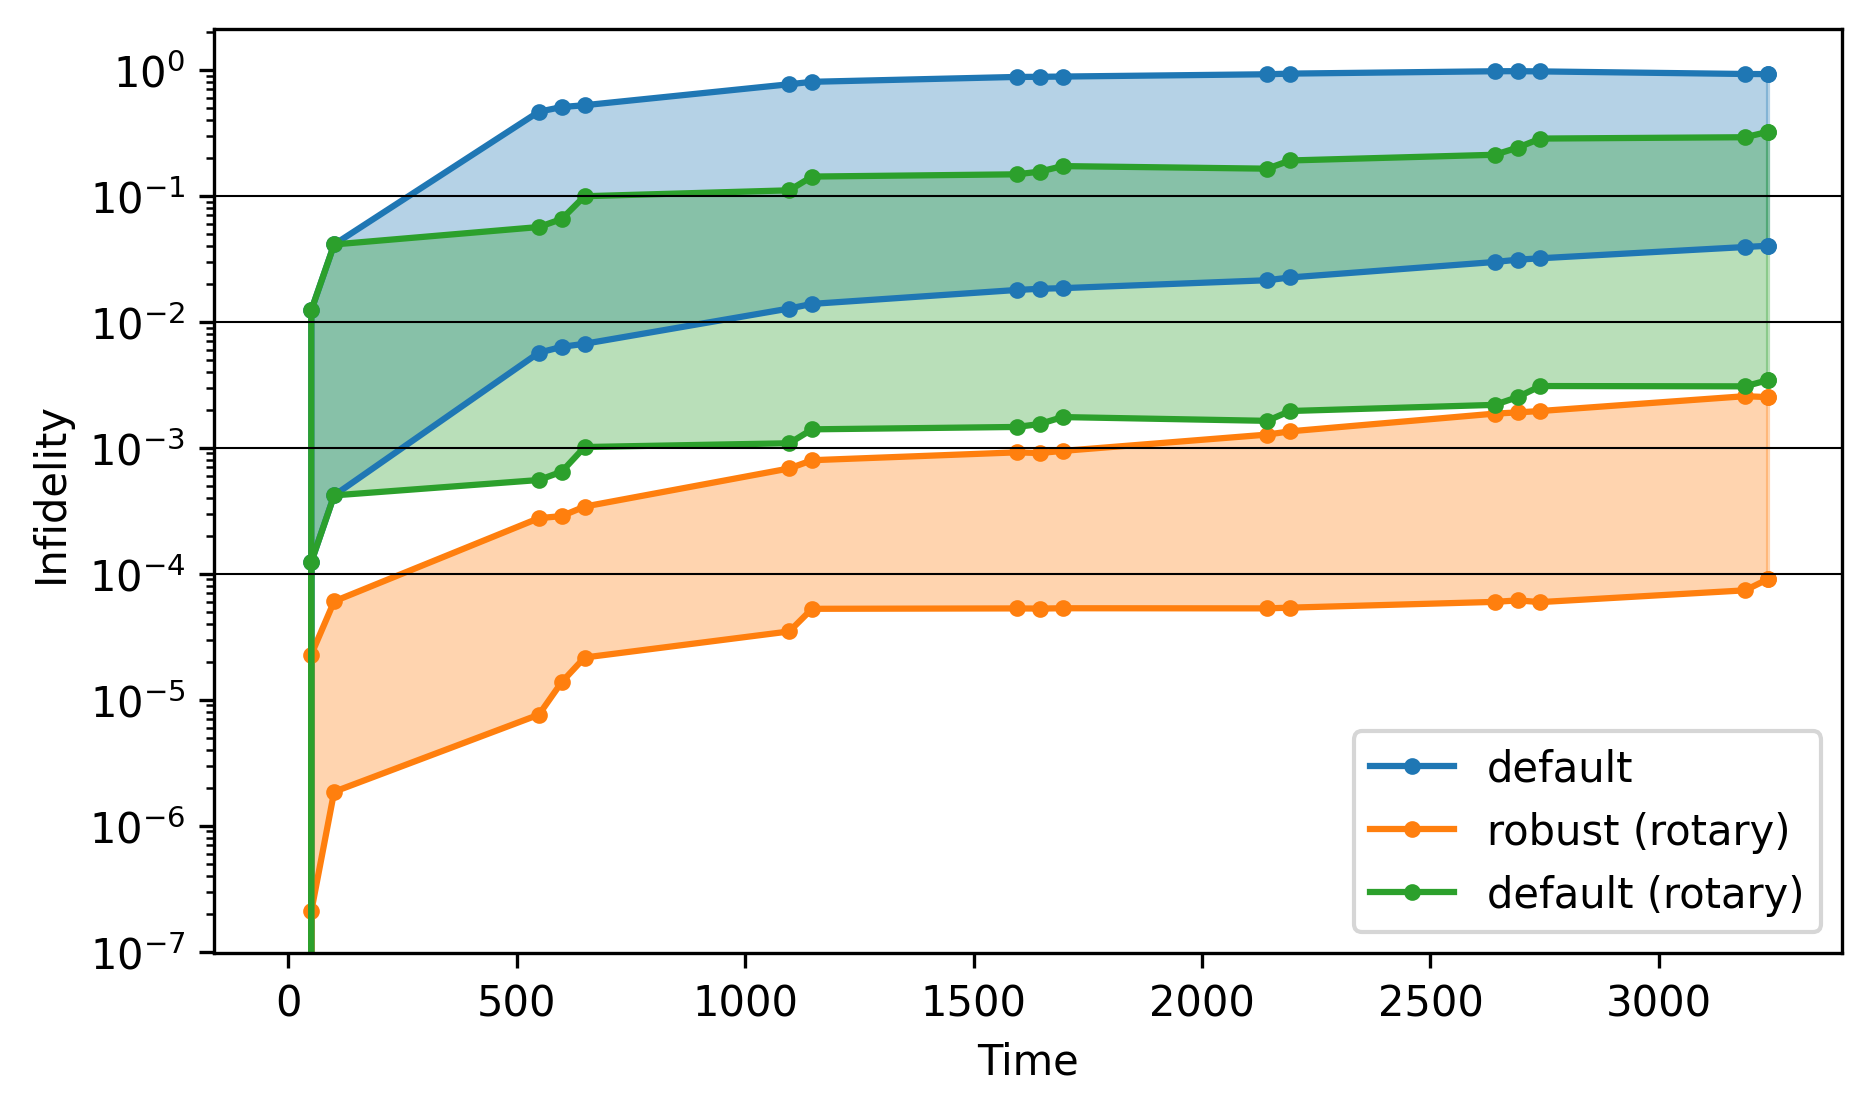

In [40]:
fig, axes = plt.subplots(1, figsize=[7, 4], dpi=300)
axes = axes if isinstance(axes, np.ndarray) else [axes]
# axes[0].set_title("Hamiltonian simulation: Crosstalk, No decoherence", loc='left')


for iax in range(1):
    ax = axes[iax]
    for i in range(len(labels)):
        res1 = two_res_x0[0][i]
        res2 = two_res_x0[1][i]
        infids1 = [0]
        infids2 = [0]
        for r1, r2, t in zip(res1.y, res2.y, Uts):
            infids1.append(1 - qk.quantum_info.process_fidelity(qk.quantum_info.Operator(r1), qk.quantum_info.Operator(t)))
            infids2.append(1 - qk.quantum_info.process_fidelity(qk.quantum_info.Operator(r2), qk.quantum_info.Operator(t)))
    
        x = np.hstack([0, *measure_times])
        ax.fill_between(x, y1=infids1, y2=infids2, color=tab10(i), alpha=0.33)
        ax.plot(x, infids1, label=labels[i], marker=".", color=tab10(i))
        ax.plot(x, infids2, marker=".", color=tab10(i))

    ax.axhline(0.1, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.01, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.001, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.0001, color="black", linestyle="-", lw=0.5)

    ax.set_xlabel("Time")
    if iax == 0:
        ax.legend(loc="lower right")
        ax.set_yscale("log")
        ax.set_ylabel("Infidelity")
    else:
        ax.set_ylabel("Infidelity")
        ax.legend(loc="upper left")
        ax.set_yscale("linear")

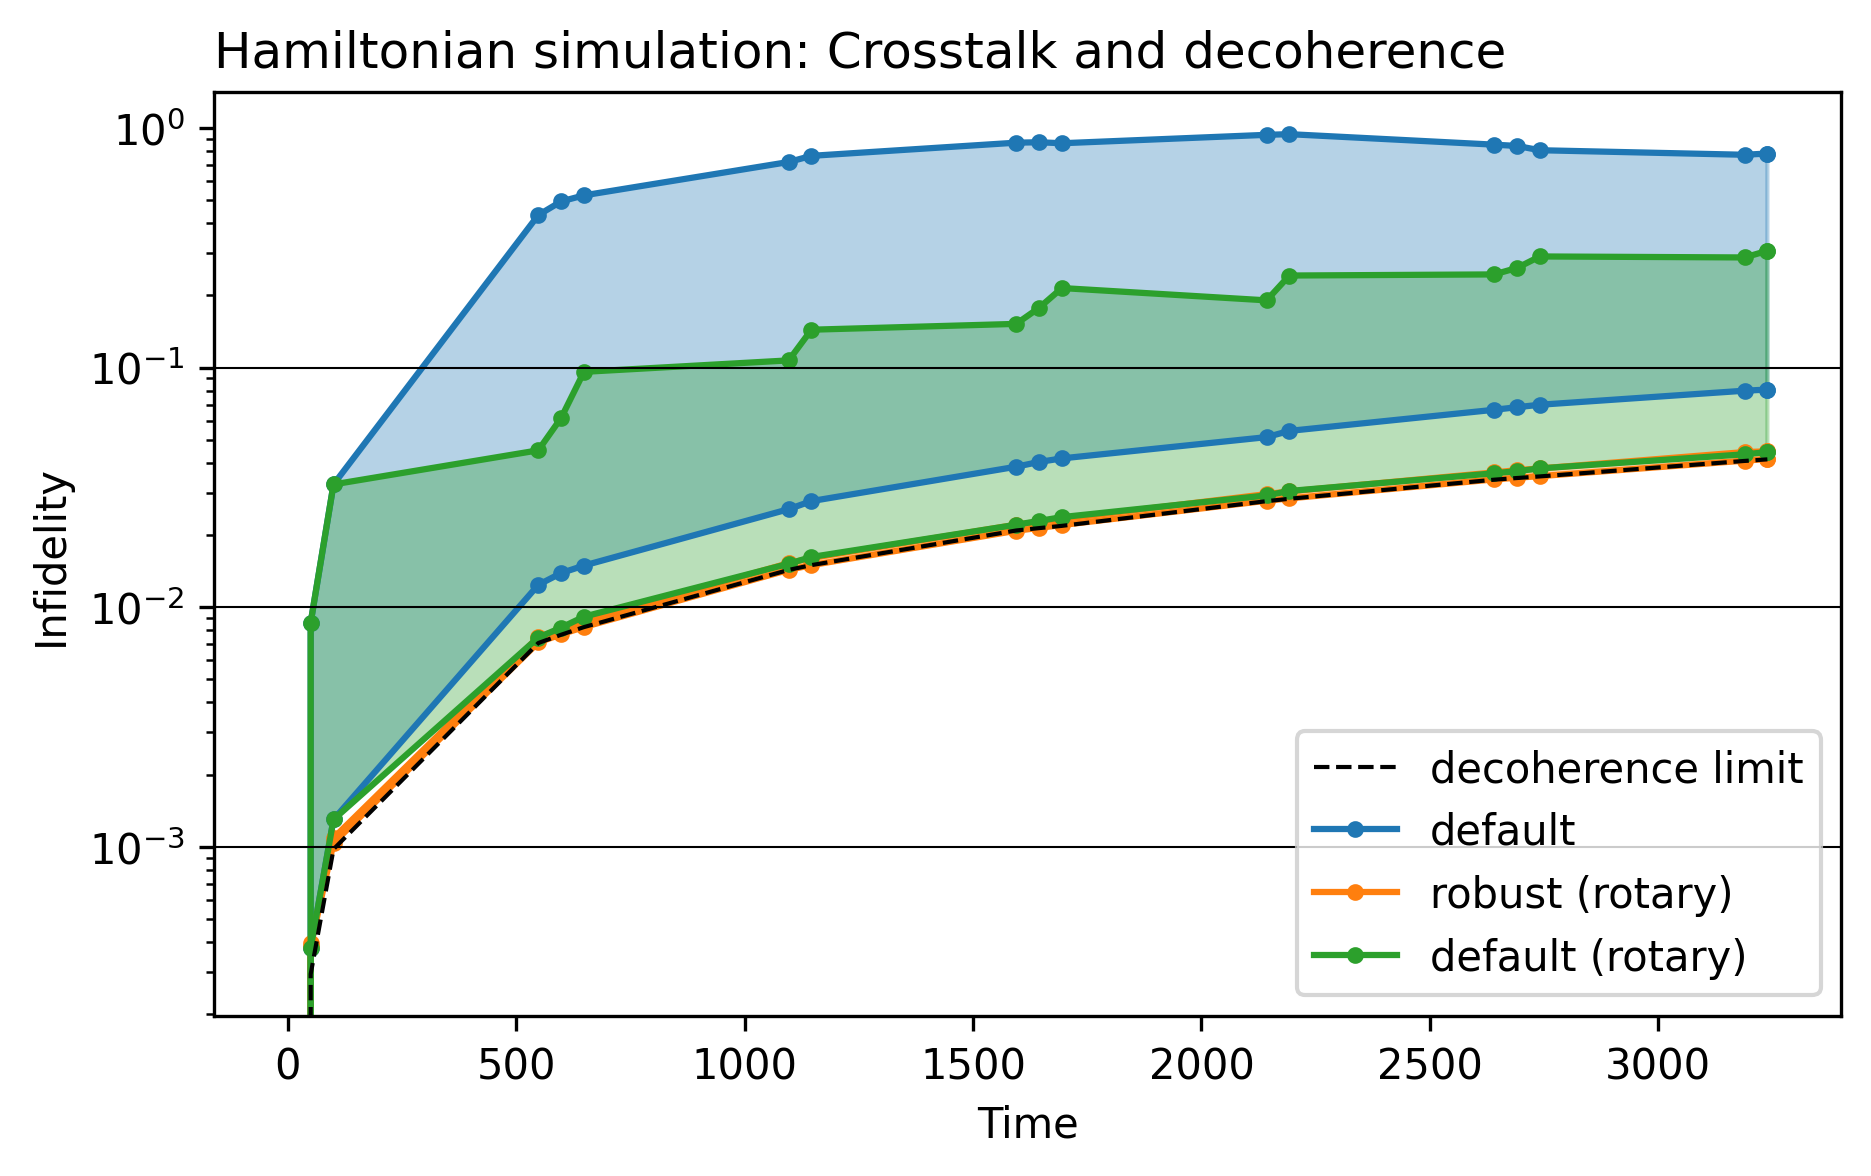

In [41]:
fig, axes = plt.subplots(1, figsize=[7, 4], dpi=300)
axes = axes if isinstance(axes, np.ndarray) else [axes]
axes[0].set_title("Hamiltonian simulation: Crosstalk and decoherence", loc='left')

yts = [y0.evolve(Ut) for Ut in Uts]
labels = ["default", "robust (rotary)", "default (rotary)"]
# labels = ["decoherence limit, default", "decoherence limit, robust (rotary)", "decoherence limit, default (rotary)"]

for iax in range(len(axes)):
    ax = axes[iax]
    tab10 = plt.get_cmap("tab10")
    for i in range(len(labels)):

        infids1 = [0]
        infids2 = [0]
        infids_decoh = [0]
        for j, t in enumerate(yts):
            infids1.append(1 - qk.quantum_info.state_fidelity(two_res_x[0][i].y[j], t))
            infids2.append(1 - qk.quantum_info.state_fidelity(two_res_x[1][i].y[j], t))
            infids_decoh.append(1 - qk.quantum_info.state_fidelity(rr.y[j], t))
        if i == 0:
            ax.plot(np.hstack([0, *measure_times]), infids_decoh, c='k', ls='--',lw=1, zorder=10, label="decoherence limit")
        x = np.hstack([0, *measure_times])
        ax.fill_between(x, y1=infids1, y2=infids2, color=tab10(i), alpha=0.33)
        ax.plot(x, infids1, label=labels[i], marker=".", color=tab10(i))
        ax.plot(x, infids2, marker=".", color=tab10(i))

    ax.axhline(0.1, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.01, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.001, color="black", linestyle="-", lw=0.5)

    ax.set_xlabel("Time")
    if iax == 0:
        ax.legend(loc="lower right")
        ax.set_yscale("log")
        ax.set_ylabel("Infidelity")
    else:
        ax.set_ylabel("Infidelity")
        ax.legend(loc="upper left")
        ax.set_yscale("linear")